# Lighter AAPL Order Books, Liquidity, Carry, and Derived Series

This notebook follows one Lighter perpetual market through nine Polaris schema surfaces:

- [Events](https://docs.polaris.supply/schemas/events)
- [L2 snapshots and updates](https://docs.polaris.supply/schemas/l2-snapshots)
- [BBO](https://docs.polaris.supply/schemas/bbo) and [depth metrics](https://docs.polaris.supply/schemas/depth-metrics)
- [Funding rates](https://docs.polaris.supply/schemas/funding-rates) and [mark prices](https://docs.polaris.supply/schemas/mark-prices)
- [Volume](https://docs.polaris.supply/schemas/volume), [VWAP](https://docs.polaris.supply/schemas/vwap), and
  [volatility](https://docs.polaris.supply/schemas/volatility)

It contrasts raw book updates with reconstructed books, then connects top-of-book quality, depth,
carry, and trade-derived measurements in a compact market-quality story.


## Setup

Run `make install` and then `make notebook` from the SDK repository’s `notebooks/` directory.

This notebook uses Python SDK 0.15.0. The legacy `/catalog` route returns HTTP 404 on the current Polaris API. Browse the saved outputs below, or use a backend compatible with SDK 0.15.0 to rerun the analysis.

The notebook uses a short live window and caps high-frequency iterators before converting them
to Pandas.


In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from polaris_data import PolarisClient

for _candidate in (Path.cwd() / "notebooks", Path.cwd()):
    if (_candidate / "_polaris.py").exists():
        sys.path.insert(0, str(_candidate))
        break

from _polaris import accessible_bounds, bounded_rows

plt.style.use("seaborn-v0_8-darkgrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 100)
warnings.filterwarnings("ignore", message=r".*snapshot coverage.*", category=UserWarning)


In [2]:
source = "lighter"
base_asset = "AAPL"
window_length = pd.Timedelta(minutes=5)
bucket_interval = "1m"


## Resolve the market and analysis window

Lighter's catalog market IDs are numeric, so the base asset is resolved from instrument metadata.


In [3]:
with PolarisClient() as client:
    catalog = client.catalog(source=source)

matches = [row for row in catalog["markets"] if (row.get("instrument") or {}).get("base") == base_asset]
if not matches:
    raise ValueError(f"Could not find {base_asset} in the {source!r} catalog")

market_info = matches[0]
market = market_info["market"]
available_start, available_end = accessible_bounds(market_info)

window_start = window_end = None
with PolarisClient() as client:
    for offset in range(288):
        candidate_end = available_end - offset * window_length
        candidate_start = max(available_start, candidate_end - window_length)
        if candidate_start >= candidate_end:
            break
        bbo_probe, _ = bounded_rows(
            client.bbo(
                source=source, market=market, from_=candidate_start, to=candidate_end,
                interval="1s", allow_gaps=True,
            ),
            1,
        )
        volume_probe = client.volume(
            source=source, market=market, from_=candidate_start, to=candidate_end,
            interval=bucket_interval, allow_gaps=True,
        )
        if bbo_probe and volume_probe:
            window_start, window_end = candidate_start, candidate_end
            break

if window_start is None:
    raise ValueError("Could not find a populated Lighter AAPL window in the last 24 hours")

print(f"Resolved {source}:{market} for {base_asset}")
print(f"Analysis window: {window_start} -> {window_end}")
pd.Series(market_info)


Resolved lighter:113 for AAPL
Analysis window: 2026-09-02 23:39:33.862000+00:00 -> 2026-09-02 23:44:33.862000+00:00


access                                                           {'public_cutoff_date': None, 'status': 'open'}
categories                                                                                               [perp]
end                                                                                    2026-09-02T23:59:33.862Z
instrument     {'base': 'AAPL', 'lot_size': '0.001', 'min_notional': '10', 'quote': None, 'tick_size': '0.001'}
market                                                                                                      113
source                                                                                                  lighter
source_type                                                                                                None
start                                                                                  2026-07-25T09:36:32.823Z
symbol                                                                                                  

## Fetch mixed events, book views, and standardized series

Complete books and raw updates are typed nested iterators, so they are consumed inside the client
context with explicit caps. BBO, depth metrics, and point series use the SDK's DataFrame output. BBO is sampled to
one-second UTC buckets to make the analysis compact.


In [4]:
with PolarisClient() as client:
    events, events_truncated = bounded_rows(
        client.events(
            source=source, market=market, from_=window_start, to=window_end,
            allow_gaps=True, materialize_orderbooks=True,
        ),
        20_000,
    )
    snapshots, snapshots_truncated = bounded_rows(
        client.l2_snapshots(
            source=source, market=market, from_=window_start, to=window_end,
            allow_gaps=True, materialize_orderbooks=True,
        ),
        5_000,
    )
    updates, updates_truncated = bounded_rows(
        client.l2_updates(
            source=source, market=market, from_=window_start, to=window_end, allow_gaps=True,
        ),
        10_000,
    )
    bbo_df = client.bbo(
        source=source, market=market, from_=window_start, to=window_end,
        interval="1s", changes_only=True, allow_gaps=True, output="dataframe",
    )
    depth_df = client.depth_metrics(
        source=source, market=market, from_=window_start, to=window_end,
        depth_pct=0.01, slippage_notional=10_000, allow_gaps=True,
        output="dataframe",
    )
    volume = client.volume(
        source=source, market=market, from_=window_start, to=window_end,
        interval=bucket_interval, allow_gaps=True,
    )
    vwap = client.vwap(
        source=source, market=market, from_=window_start, to=window_end,
        interval=bucket_interval, allow_gaps=True,
    )
    volatility = client.volatility(
        source=source, market=market, from_=window_start, to=window_end,
        interval=bucket_interval, allow_gaps=True,
    )
    funding_df = client.funding_rates(
        source=source, market=market, from_=window_start, to=window_end,
        allow_gaps=True, output="dataframe",
    )
    mark_df = client.mark_prices(
        source=source, market=market, from_=window_start, to=window_end,
        allow_gaps=True, output="dataframe",
    )

row_counts = pd.DataFrame([
    ("events", len(events), events_truncated),
    ("l2_snapshots", len(snapshots), snapshots_truncated),
    ("l2_updates", len(updates), updates_truncated),
    ("bbo", len(bbo_df), False),
    ("depth_metrics", len(depth_df), False),
    ("volume", len(volume), False),
    ("vwap", len(vwap), False),
    ("volatility", len(volatility), False),
    ("funding_rates", len(funding_df), False),
    ("mark_prices", len(mark_df), False),
], columns=["schema", "rows", "hit_notebook_cap"])
row_counts


,schema,rows,hit_notebook_cap
0,events,992,False
1,l2_snapshots,460,False
2,l2_updates,460,False
3,bbo,48,False
4,depth_metrics,460,False
5,volume,1,False
6,vwap,1,False
7,volatility,1,False
8,funding_rates,105,False
9,mark_prices,0,False


## Inspect envelope and order-book behavior

V2 rows use `collector_timestamp`; legacy rows use `timestamp`. Materialized snapshots contain
a complete sorted book after every applicable update, while `l2_updates(...)` preserves the sparse
stored update. The table below makes that allocation and state-management tradeoff visible.


In [5]:
event_types = pd.Series([row.get("type", "unknown") for row in events], name="event_type").value_counts()

def level_count(row, side):
    return len((row.get("data") or {}).get(side, []))

book_comparison = pd.DataFrame([
    {
        "view": "materialized snapshots",
        "rows": len(snapshots),
        "median_bid_levels": pd.Series([level_count(row, "bids") for row in snapshots]).median(),
        "median_ask_levels": pd.Series([level_count(row, "asks") for row in snapshots]).median(),
        "snapshot_origin_share": pd.Series([
            (row.get("data") or {}).get("is_snapshot") for row in snapshots
        ], dtype="boolean").mean(),
    },
    {
        "view": "raw updates",
        "rows": len(updates),
        "median_bid_levels": pd.Series([level_count(row, "bids") for row in updates]).median(),
        "median_ask_levels": pd.Series([level_count(row, "asks") for row in updates]).median(),
        "snapshot_origin_share": pd.Series([
            (row.get("data") or {}).get("is_snapshot") for row in updates
        ], dtype="boolean").mean(),
    },
])

display(event_types.rename_axis("type").to_frame("rows"))
book_comparison


,rows
type,
point,525
orderbook,460
trade,7


,view,rows,median_bid_levels,median_ask_levels,snapshot_origin_share
0,materialized snapshots,460,77.0,45.0,0.002174
1,raw updates,460,2.0,0.0,0.002174


## Normalize liquidity and derived series

BBO exposes the top of book. Depth metrics add one-percent depth, imbalance, and estimated slippage
for a $10,000 notional. Volume, VWAP, and volatility share UTC bucket timestamps and can be joined.


In [6]:
if not bbo_df.empty:
    bbo_df["timestamp"] = pd.to_datetime(bbo_df["timestamp"], utc=True)
    bbo_df["mid_price"] = (bbo_df["bid_price"] + bbo_df["ask_price"]) / 2
    bbo_df["spread_bps"] = (bbo_df["ask_price"] - bbo_df["bid_price"]) / bbo_df["mid_price"] * 10_000

if not depth_df.empty:
    depth_df["timestamp"] = pd.to_datetime(depth_df["timestamp"], utc=True)
    depth_df["worst_slippage_bps"] = depth_df[["buy_slippage_bps", "sell_slippage_bps"]].max(axis=1)

def bucket_frame(rows, value_name):
    frame = pd.DataFrame(rows)
    if frame.empty:
        return pd.DataFrame(columns=["timestamp", value_name])
    frame["timestamp"] = pd.to_datetime(frame["timestamp"], unit="ms", utc=True)
    return frame

volume_df = bucket_frame(volume, "volume").rename(columns={"volume": "bucket_volume"})
vwap_df = bucket_frame(vwap, "vwap")
volatility_df = bucket_frame(volatility, "volatility")
bucket_df = (
    volume_df.merge(vwap_df, on="timestamp", how="outer")
    .merge(volatility_df, on="timestamp", how="outer")
    .sort_values("timestamp")
)

liquidity_summary = pd.DataFrame([{
    "median_spread_bps": bbo_df.get("spread_bps", pd.Series(dtype=float)).median(),
    "median_bid_depth_1pct": depth_df.get("bid_depth_notional", pd.Series(dtype=float)).median(),
    "median_ask_depth_1pct": depth_df.get("ask_depth_notional", pd.Series(dtype=float)).median(),
    "median_imbalance": depth_df.get("depth_imbalance", pd.Series(dtype=float)).median(),
    "median_worst_slippage_bps_10k": depth_df.get("worst_slippage_bps", pd.Series(dtype=float)).median(),
}])
liquidity_summary


,median_spread_bps,median_bid_depth_1pct,median_ask_depth_1pct,median_imbalance,median_worst_slippage_bps_10k
0,1.385265,813730.033238,813552.237588,0.000487,1.043381


## Top-of-book and depth quality

Spread measures immediacy at the top of book; imbalance and notional slippage use the reconstructed
depth behind it. Empty panels remain explicit when a live public window lacks a derived series.


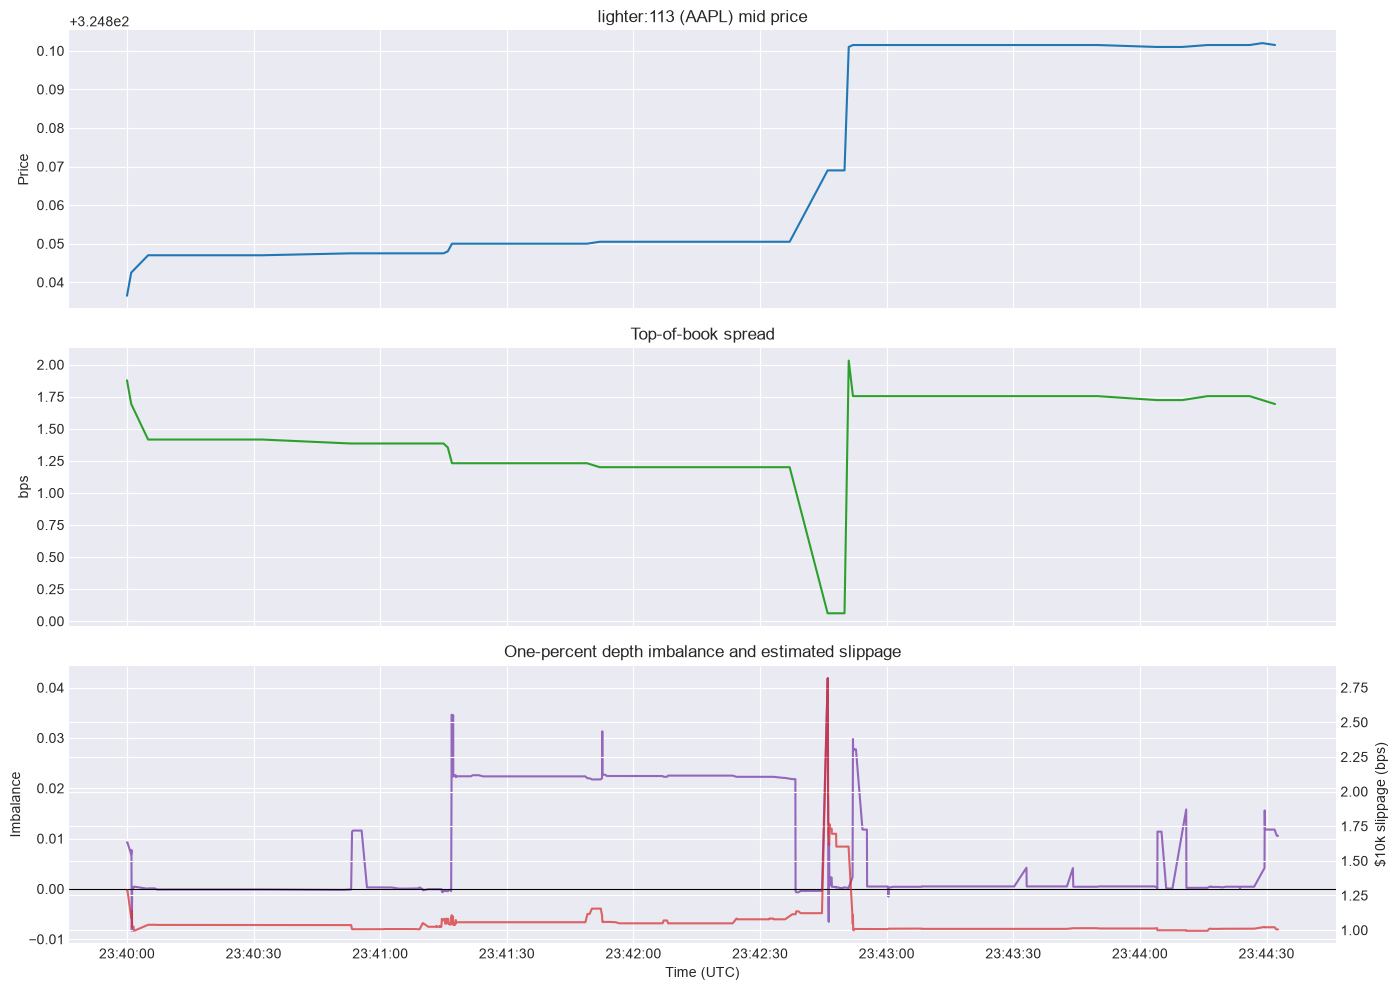

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

if bbo_df.empty:
    axes[0].text(0.5, 0.5, "No BBO rows", ha="center", va="center", transform=axes[0].transAxes)
    axes[1].text(0.5, 0.5, "No BBO rows", ha="center", va="center", transform=axes[1].transAxes)
else:
    axes[0].plot(bbo_df["timestamp"], bbo_df["mid_price"], color="#1f77b4")
    axes[1].plot(bbo_df["timestamp"], bbo_df["spread_bps"], color="#2ca02c")
axes[0].set_title(f"{source}:{market} ({base_asset}) mid price")
axes[0].set_ylabel("Price")
axes[1].set_title("Top-of-book spread")
axes[1].set_ylabel("bps")

if depth_df.empty:
    axes[2].text(0.5, 0.5, "No depth-metric rows", ha="center", va="center", transform=axes[2].transAxes)
else:
    axes[2].plot(depth_df["timestamp"], depth_df["depth_imbalance"], color="#9467bd", label="imbalance")
    slippage_axis = axes[2].twinx()
    slippage_axis.plot(depth_df["timestamp"], depth_df["worst_slippage_bps"], color="#d62728", alpha=0.7, label="worst slippage")
    slippage_axis.set_ylabel("$10k slippage (bps)")
axes[2].axhline(0, color="black", linewidth=0.8)
axes[2].set_title("One-percent depth imbalance and estimated slippage")
axes[2].set_ylabel("Imbalance")
axes[2].set_xlabel("Time (UTC)")

plt.tight_layout()
plt.show()


## Carry series and trade-derived buckets

Funding and mark-price coverage is venue-dependent. The notebook reports empty DataFrames instead
of assuming every market exposes both series, then visualizes populated values alongside VWAP,
volume, and realized volatility.


Funding rows: 105
Mark-price rows: 0
This public Lighter window does not expose mark-price rows.


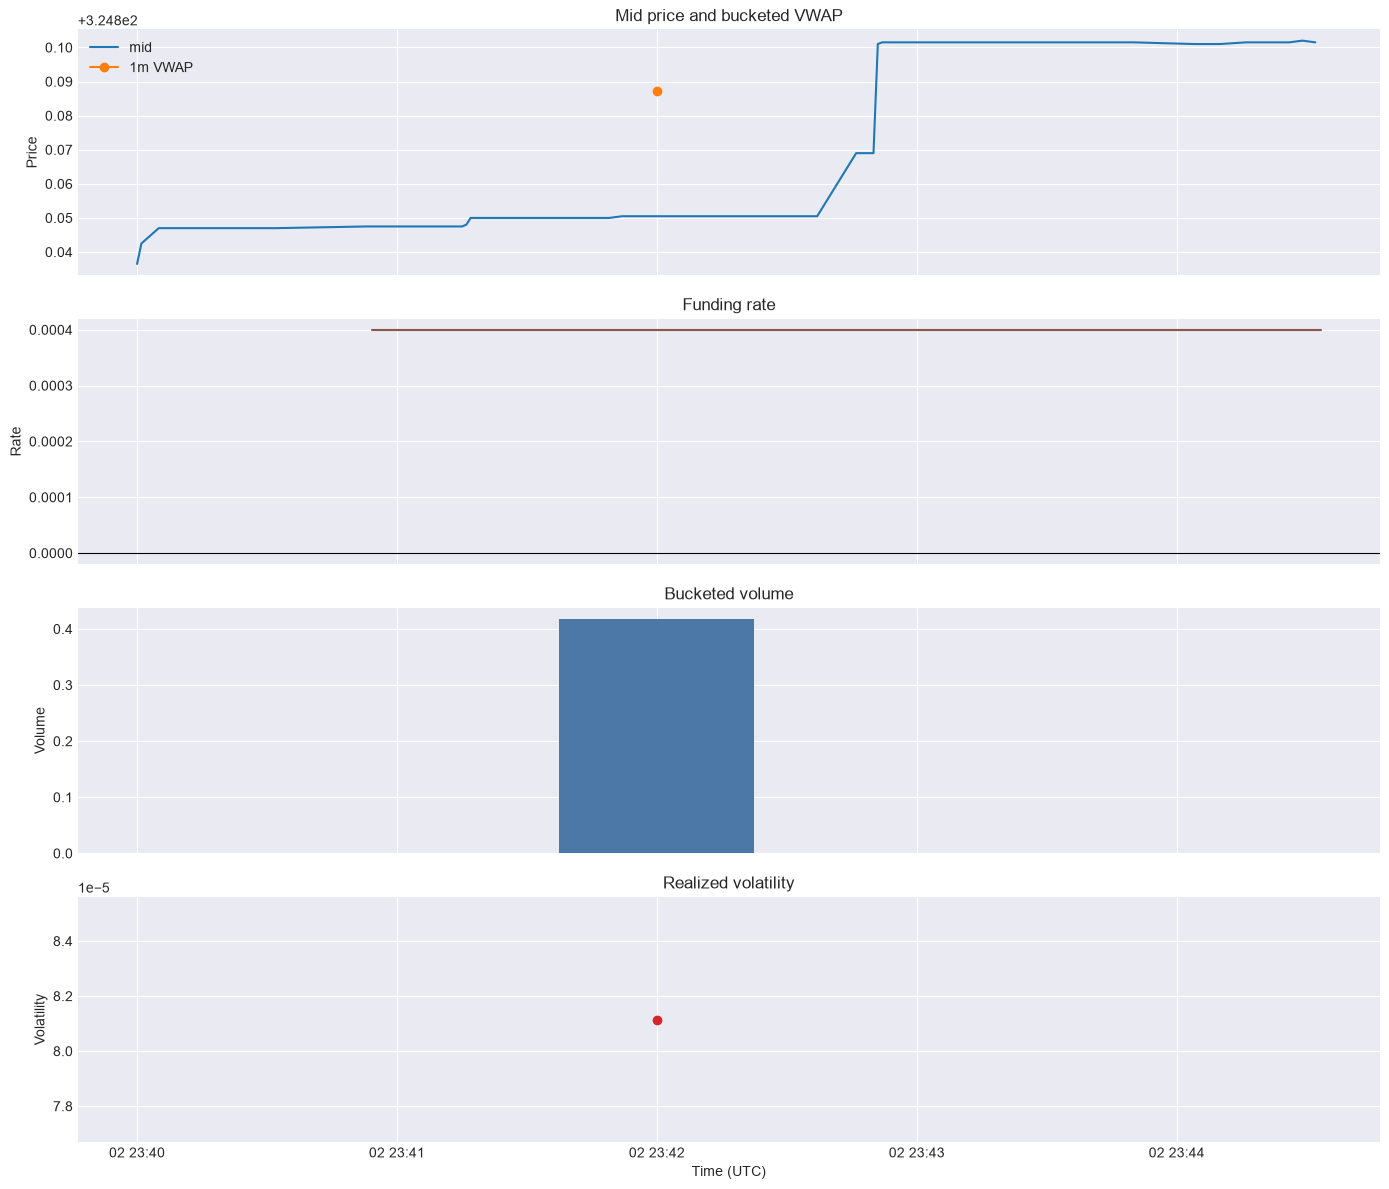

In [8]:
print(f"Funding rows: {len(funding_df):,}")
print(f"Mark-price rows: {len(mark_df):,}")
if funding_df.empty:
    print("This public Lighter window does not expose funding-rate rows.")
if mark_df.empty:
    print("This public Lighter window does not expose mark-price rows.")

fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)

if not bbo_df.empty:
    axes[0].plot(bbo_df["timestamp"], bbo_df["mid_price"], color="#1f77b4", label="mid")
if not bucket_df.empty and "vwap" in bucket_df:
    axes[0].plot(bucket_df["timestamp"], bucket_df["vwap"], color="#ff7f0e", marker="o", label="1m VWAP")
if not mark_df.empty and "mark_price" in mark_df:
    axes[0].plot(pd.to_datetime(mark_df["timestamp"], utc=True), mark_df["mark_price"], color="#9467bd", label="mark")
axes[0].set_title("Mid price and bucketed VWAP")
axes[0].set_ylabel("Price")
handles, labels = axes[0].get_legend_handles_labels()
if handles:
    axes[0].legend(handles, labels, loc="best")

if funding_df.empty or "funding_rate" not in funding_df:
    axes[1].text(0.5, 0.5, "No funding-rate rows", ha="center", va="center", transform=axes[1].transAxes)
else:
    axes[1].plot(pd.to_datetime(funding_df["timestamp"], utc=True), funding_df["funding_rate"], color="#8c564b")
    axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Funding rate")
axes[1].set_ylabel("Rate")

if bucket_df.empty:
    axes[2].text(0.5, 0.5, "No bucketed volume", ha="center", va="center", transform=axes[2].transAxes)
else:
    axes[2].bar(bucket_df["timestamp"], bucket_df.get("bucket_volume"), width=pd.Timedelta(seconds=45), color="#4c78a8")
axes[2].set_title("Bucketed volume")
axes[2].set_ylabel("Volume")

if bucket_df.empty or "volatility" not in bucket_df:
    axes[3].text(0.5, 0.5, "No volatility rows", ha="center", va="center", transform=axes[3].transAxes)
else:
    axes[3].plot(bucket_df["timestamp"], bucket_df["volatility"], color="#d62728", marker="o")
axes[3].set_title("Realized volatility")
axes[3].set_ylabel("Volatility")
axes[3].set_xlabel("Time (UTC)")

plt.tight_layout()
plt.show()
